
COMBINED BATHYMETRY + WIND STRESS ANOMALY + DOT PLOT
Bathymetry contour: 3500 m
Wind stress opacity: 1.0
DOT contour level: -2.25 m

Loading wind stress data...

=== Creating 1980-2009 Average ===
Loading era5_monthly_surface_stress_1980.nc...


/Users/nbcoffey/miniconda3/lib/python3.12/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.dylib'.
dlopen(libgmt.dylib, 0x0006): tried: 'libgmt.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibgmt.dylib' (no such file), '/Users/nbcoffey/miniconda3/lib/python3.12/lib-dynload/../../libgmt.dylib' (no such file), '/Users/nbcoffey/miniconda3/bin/../lib/libgmt.dylib' (no such file), '/usr/lib/libgmt.dylib' (no such file, not in dyld cache), 'libgmt.dylib' (no such file), '/usr/local/lib/libgmt.dylib' (no such file), '/usr/lib/libgmt.dylib' (no such file, not in dyld cache)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


Loading era5_monthly_surface_stress_1981.nc...
Loading era5_monthly_surface_stress_1982.nc...
Loading era5_monthly_surface_stress_1983.nc...
Loading era5_monthly_surface_stress_1984.nc...
Loading era5_monthly_surface_stress_1985.nc...
Loading era5_monthly_surface_stress_1986.nc...
Loading era5_monthly_surface_stress_1987.nc...
Loading era5_monthly_surface_stress_1988.nc...
Loading era5_monthly_surface_stress_1989.nc...
Loading era5_monthly_surface_stress_1990.nc...
Loading era5_monthly_surface_stress_1991.nc...
Loading era5_monthly_surface_stress_1992.nc...
Loading era5_monthly_surface_stress_1993.nc...
Loading era5_monthly_surface_stress_1994.nc...
Loading era5_monthly_surface_stress_1995.nc...
Loading era5_monthly_surface_stress_1996.nc...
Loading era5_monthly_surface_stress_1997.nc...
Loading era5_monthly_surface_stress_1998.nc...
Loading era5_monthly_surface_stress_1999.nc...
Loading era5_monthly_surface_stress_2000.nc...
Loading era5_monthly_surface_stress_2001.nc...
Loading era5_

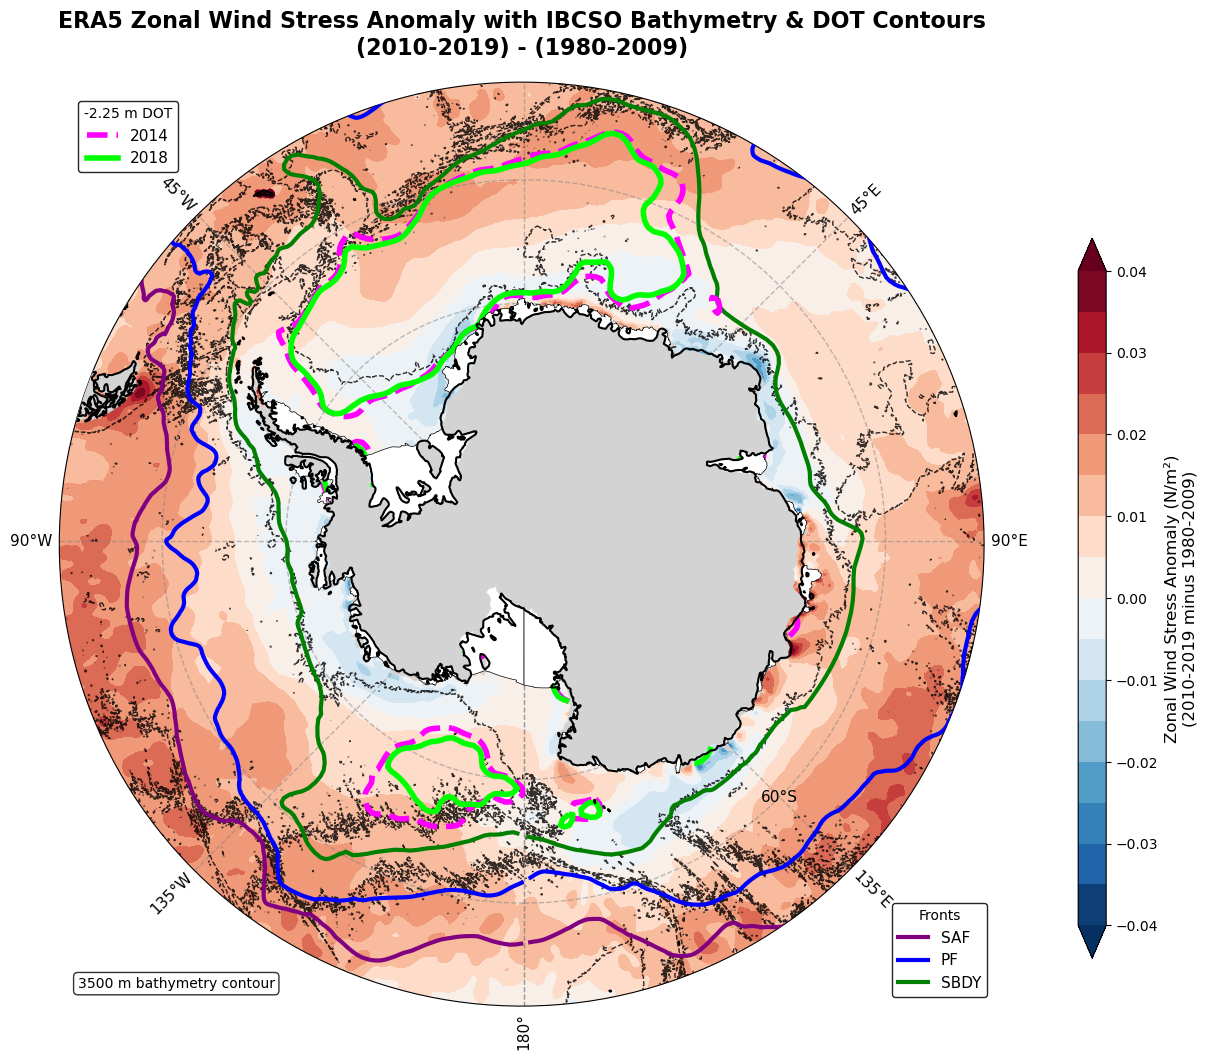


COMPLETE!


In [1]:
import cartopy.feature as cfeature
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.path import Path
from matplotlib.collections import LineCollection
import matplotlib.lines as mlines
import xarray as xr
import numpy as np
import pandas as pd
import rasterio
import os

# ——— USER TOGGLES ——————————————————————————————————————
HIGH_RES          = True      # True = full-res (slow), False = subsampled (fast)
SUBSAMPLE         = 1 if HIGH_RES else 4 # Used for development
BOTTOM_LAT        = -52        # Northern limit of plot
BATHY_INTERVAL_M  = 3500       # Bathymetry contour in meters
WIND_ALPHA        = 1.0        # Opacity of wind stress field (1.0 = opaque)
DOT_LEVEL         = -2.25      # DOT contour level in meters
# ——————————————————————————————————————————————————————

def load_and_process_year(filepath, lat_max=-40, lat_min=-80):
    """Load and process wind stress data for one year."""
    print(f"Loading {filepath}...")
    ds = xr.open_dataset(filepath)
    
    # Time average
    ds_mean = ds.mean(dim='valid_time')
    
    lon_coord = 'longitude' if 'longitude' in ds.coords else 'lon'
    lat_coord = 'latitude' if 'latitude' in ds.coords else 'lat'
    
    # Select latitude range
    ds_mean_south = ds_mean.where(
        (ds_mean[lat_coord] <= lat_max) & (ds_mean[lat_coord] >= lat_min), 
        drop=True
    )
    
    # Convert from accumulated to instantaneous
    seconds_per_day = 86400.0
    tau_x = ds_mean_south['ewss'] / seconds_per_day
    tau_y = ds_mean_south['nsss'] / seconds_per_day
    
    return {'tau_x': tau_x, 'tau_y': tau_y, 
            'lon_coord': lon_coord, 'lat_coord': lat_coord}

def load_multi_year_average(year_start, year_end, lat_max=-40, lat_min=-80):
    """Load and average wind stress data across multiple years."""
    print(f"\n=== Creating {year_start}-{year_end} Average ===")
    
    tau_x_list = []
    tau_y_list = []
    
    for year in range(year_start, year_end + 1):
        filepath = f'era5_monthly_surface_stress_{year}.nc'
        
        if not os.path.exists(filepath):
            print(f"WARNING: {filepath} not found, skipping...")
            continue
            
        data = load_and_process_year(filepath, lat_max=lat_max, lat_min=lat_min)
        tau_x_list.append(data['tau_x'])
        tau_y_list.append(data['tau_y'])
    
    if not tau_x_list:
        raise FileNotFoundError(f"No ERA5 files found for {year_start}-{year_end}")
    
    # Average across all years
    print(f"Averaging {len(tau_x_list)} years...")
    tau_x_avg = sum(tau_x_list) / len(tau_x_list)
    tau_y_avg = sum(tau_y_list) / len(tau_y_list)
    
    return {'tau_x': tau_x_avg, 'tau_y': tau_y_avg,
            'lon_coord': data['lon_coord'], 'lat_coord': data['lat_coord']}

def load_front_segments(filepath):
    """Load front data from text file."""
    segs, pts = [], []
    for L in open(filepath):
        s = L.strip()
        if s == "X":
            if pts:
                segs.append(np.array(pts, dtype=float))
                pts = []
        else:
            parts = s.split()
            if len(parts)==2:
                try: 
                    pts.append([float(parts[0]), float(parts[1])])
                except ValueError: 
                    pass
    if pts: 
        segs.append(np.array(pts, dtype=float))
    return segs

def set_circular_boundary(ax):
    """Add circular boundary to polar plot."""
    theta = np.linspace(0, 2*np.pi, 200)
    verts = np.column_stack([0.5 + 0.5*np.cos(theta),
                             0.5 + 0.5*np.sin(theta)])
    ax.set_boundary(Path(verts), transform=ax.transAxes)

def main():
    print("\n" + "="*70)
    print("COMBINED BATHYMETRY + WIND STRESS ANOMALY + DOT PLOT")
    print("="*70)
    print(f"Bathymetry contour: {BATHY_INTERVAL_M} m")
    print(f"Wind stress opacity: {WIND_ALPHA}")
    print(f"DOT contour level: {DOT_LEVEL} m")
    
    # ------------------------------------------------------------------
    # 1) Load wind stress data
    # ------------------------------------------------------------------
    print("\nLoading wind stress data...")
    climatology_data = load_multi_year_average(1980, 2009, lat_max=-40, lat_min=-80)
    decadal_data = load_multi_year_average(2010, 2019, lat_max=-40, lat_min=-80)
    
    # Calculate anomaly
    tau_x_anomaly = decadal_data['tau_x'] - climatology_data['tau_x']
    lon_coord = climatology_data['lon_coord']
    lat_coord = climatology_data['lat_coord']
    
    print(f"\nAnomaly range: [{float(tau_x_anomaly.min()):.4f}, {float(tau_x_anomaly.max()):.4f}] N/m²")
    
    # ------------------------------------------------------------------
    # 2) Load IBCSO bathymetry
    # ------------------------------------------------------------------
    print("\nLoading IBCSO bathymetry...")
    with rasterio.open("/Users/nbcoffey/Downloads/IBCSO_bed/IBCSO_bed.tif") as src:
        ibcso_data = src.read(1)
        t = src.transform
        # Projected (polar stereographic) pixel-center coordinates in meters, 1D,
        # matching the [::SUBSAMPLE] slicing below exactly
        x_bathy = t.c + t.a * (np.arange(0, src.width,  SUBSAMPLE) + 0.5)
        y_bathy = t.f + t.e * (np.arange(0, src.height, SUBSAMPLE) + 0.5)
    
    # Subsample for speed
    ibcso_ds = ibcso_data[::SUBSAMPLE, ::SUBSAMPLE]
    
    print(f"Bathymetry range: [{ibcso_ds.min()}, {ibcso_ds.max()}] m")
    
    # ------------------------------------------------------------------
    # 3) Load DOT data
    # ------------------------------------------------------------------
    print("\nLoading DOT data...")
    dot_raw = xr.open_dataset("/Users/nbcoffey/Downloads/Full_DOT_data_Anto.nc", decode_times=False)
    
    # Decode times (days since 2000-01-01) and assign as the "time" coordinate
    dates = pd.to_datetime(dot_raw["time"].values, unit="D", origin="2000-01-01")
    dot = dot_raw.assign_coords(time=("time", dates))
    
    # Compute the 12-month mean for each calendar year
    yearly = dot["DOT_smoothed"].groupby("time.year").mean(dim="time")
    
    # Pick the years you want
    dot_years = [2014, 2018]
    dot_colors = {2014: "magenta", 2018: "lime"}
    line_styles = ['--', '-']
    
    # Get the 2D averaged arrays
    arr_means = [yearly.sel(year=yr).values for yr in dot_years]
    
    # Get lon/lat arrays and project them
    lon_dot = dot_raw["lons"].values
    lat_dot = dot_raw["lats"].values
    proj = ccrs.SouthPolarStereo()
    tf = ccrs.PlateCarree()
    xy = proj.transform_points(tf, lon_dot, lat_dot)
    x_proj, y_proj = xy[..., 0], xy[..., 1]
    
    # DOT doesn't need subsample
    x_proj_ds = x_proj # [::SUBSAMPLE, ::SUBSAMPLE]
    y_proj_ds = y_proj # [::SUBSAMPLE, ::SUBSAMPLE]
    
    # ------------------------------------------------------------------
    # 4) Define frontal boundaries
    # ------------------------------------------------------------------
    frontal_files = {
        "SAF":  ("/Users/nbcoffey/Downloads/orsi_contours/saf.txt",  'purple'),
        "PF":   ("/Users/nbcoffey/Downloads/orsi_contours/pf.txt",   'blue'),
        "SBDY": ("/Users/nbcoffey/Downloads/orsi_contours/sbdy.txt", 'green')
    }
    
    # ------------------------------------------------------------------
    # 5) Create combined plot
    # ------------------------------------------------------------------
    print("\nCreating combined plot...")
    
    fig = plt.figure(figsize=(14, 12))
    ax = plt.axes(projection=proj)
    
# a) Plot wind stress anomaly FIRST (underneath)
    # diff_levels = np.linspace(-0.05, 0.05, 21)
    diff_levels = np.linspace(-0.04, 0.04, 17)

    # Add cyclic point (copy of 0° at 360°) to close the gap at the Greenwich meridian
    tau_x_anom_cyc, lon_cyc = add_cyclic_point(
        tau_x_anomaly.values,
        coord=tau_x_anomaly[lon_coord].values
    )

    im = ax.contourf(
        lon_cyc,
        tau_x_anomaly[lat_coord].values,
        tau_x_anom_cyc,
        levels=diff_levels,
        cmap='RdBu_r',
        extend='both',
        transform=tf,
        alpha=WIND_ALPHA,
        zorder=1
    )
    
    # b) Plot bathymetry contours (1D projected x/y; no meshgrid needed)
    bathy_levels = [-BATHY_INTERVAL_M]
    
    print(f"Plotting bathymetry contours at: {bathy_levels} m")
    
    cs = ax.contour(
        x_bathy,
        y_bathy,
        ibcso_ds,
        levels=bathy_levels,
        colors='black',
        linewidths=1.0,
        alpha=0.8,
        transform=ccrs.SouthPolarStereo(true_scale_latitude=-65),
        zorder=2
    )
    
    # c) Add land
    ax.add_feature(cfeature.LAND, color='lightgray', zorder=3)
    
    # Try to add ice shelves with white fill to mask data underneath
    try:
        ax.add_feature(
            cfeature.NaturalEarthFeature(
                'physical', 'antarctic_ice_shelves_polys', '50m',
                edgecolor='black', facecolor='white', linewidth=0.5
            ),
            zorder=13  # Above DOT contours
        )
    except Exception as e:
        print("Warning: Could not load Antarctic ice shelves {e}")
    
    # Add coastlines on top
    ax.coastlines(resolution='50m', linewidth=1.5, zorder=14)
    
    # d) Add fronts
    print("\nLoading frontal boundaries...")
    front_handles = []
    for lbl, (fpath, col) in frontal_files.items():
        try:
            segs = load_front_segments(fpath)
            lc = LineCollection(segs, colors=col, linewidths=3,
                              transform=ccrs.PlateCarree(), zorder=10)
            ax.add_collection(lc)
            front_handles.append(mlines.Line2D([],[],color=col,linewidth=3,label=lbl))
            print(f"Loaded {lbl} front")
        except Exception as e:
            print(f"Warning: Could not load {lbl} from {fpath}: {e}")
    
    # e) Add DOT contours
    print("\nPlotting DOT contours...")
    dot_handles = []
    for arr, yr, ls in zip(arr_means, dot_years, line_styles):
        arr_ds = np.ma.masked_invalid(arr) # [::SUBSAMPLE, ::SUBSAMPLE])
        cs_dot = ax.contour(
            x_proj_ds, y_proj_ds, arr_ds,
            levels=[DOT_LEVEL],
            colors=[dot_colors[yr]],
            linewidths=4,
            linestyles=ls,
            transform=proj,
            zorder=11
        )
        dot_handles.append(
            mlines.Line2D([],[], color=dot_colors[yr], linewidth=4,
                          linestyle=ls, label=f"{yr}")
        )
    
    # f) Add gridlines
    gl = ax.gridlines(
        crs=tf, 
        draw_labels=True,
        linewidth=1.0, 
        color='gray', 
        alpha=0.5,
        linestyle='--', 
        zorder=4
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 45))
    gl.ylocator = mticker.FixedLocator(np.arange(-80, -30, 10))
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 11, 'color': 'black'}
    gl.ylabel_style = {'size': 11, 'color': 'black'}
    
    # g) Set extent
    ax.set_extent([-180, 180, -90, BOTTOM_LAT], crs=tf)
    
    # h) Add colorbar for wind stress anomaly
    fig.subplots_adjust(right=0.88)
    cax = fig.add_axes([0.90, 0.15, 0.02, 0.6])
    cbar = fig.colorbar(im, cax=cax, orientation='vertical', extend='both')
    cbar.set_label('Zonal Wind Stress Anomaly (N/m²)\n(2010-2019 minus 1980-2009)', 
                   fontsize=12)
    cbar.ax.tick_params(labelsize=10)
    
    # i) Add title
    ax.set_title(
        'ERA5 Zonal Wind Stress Anomaly with IBCSO Bathymetry & DOT Contours\n' +
        '(2010-2019) - (1980-2009)',
        fontsize=16, 
        pad=20,
        fontweight='bold'
    )
    
    # j) Add circular boundary
    set_circular_boundary(ax)
    
    # k) Add separate legends
    # DOT legend (upper left)
    if dot_handles:
        legend1 = ax.legend(handles=dot_handles,
                           loc='upper left', bbox_to_anchor=(0.02, 0.98),
                           borderaxespad=0.0, fontsize=11,
                           framealpha=0.85, facecolor='white',
                           edgecolor='black', fancybox=True,
                           title=f'{DOT_LEVEL} m DOT')
        ax.add_artist(legend1)  # Add first legend to axes
    
    # Fronts legend (bottom right, beside the map)
    if front_handles:
        legend2 = ax.legend(handles=front_handles,
                           loc='lower left', bbox_to_anchor=(0.90, 0.01),
                           borderaxespad=0.0, fontsize=11,
                           framealpha=0.85, facecolor='white',
                           edgecolor='black', fancybox=True,
                           title='Fronts')
    
    # l) Add text annotation for bathymetry
    ax.text(
        0.02, 0.02,
        f'{BATHY_INTERVAL_M} m bathymetry contour',
        transform=ax.transAxes,
        fontsize=10,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8),
        zorder=12
    )
    
    # Save
    fig_dir = 'plots'
    os.makedirs(fig_dir, exist_ok=True)
    
    # 1. Save PNG
    out_png = os.path.join(fig_dir, 'wind_stress_anomaly_with_bathymetry_fronts_and_DOT.png')
    plt.savefig(out_png, dpi=300, bbox_inches='tight', facecolor='white', edgecolor='none')
    print(f"\nPNG saved to {out_png}")

    # 2. Save PDF (ready to run through pdf2png2pdf)
    out_pdf = os.path.join(fig_dir, 'wind_stress_anomaly_with_bathymetry_fronts_and_DOT.pdf')
    plt.savefig(out_pdf, bbox_inches='tight', facecolor='white', edgecolor='none')
    print(f"PDF saved to {out_pdf}")
    
    plt.show()
    
    print("\n" + "="*70)
    print("COMPLETE!")
    print("="*70)

if __name__ == '__main__':
    main()